# Week 10: Clustering with K Means
**Rupal Paliwal, Mod C, Semester 1**

**Data:** Part 1 uses the box office data (4,803 films). Part 2 uses the MovieLens tag genome for the 2,179 films from 2000 to 2015 that matched MovieLens.

**Question:** Do films fall into natural groups? Part 1 looks for **market groups** (how much a film earned and where), and Part 2 looks for **content groups** (what kind of film it is) and asks how revenue differs between them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Part 1: Market Groups (Box Office Data)

## 1. Choose the features

Four numbers describe a film's market: log worldwide gross, the share of gross earned in the U.S. (`Domestic %`), log vote count (audience reach), and rating.

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')
data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

X = pd.DataFrame({'log_votes': np.log1p(data['Vote_Count']), 'rating': data['Rating_num'], 'year': data['Year']}, index=data.index)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)
X = pd.concat([X, genres, langs], axis=1)
F = pd.DataFrame({'log_gross': np.log(data['$Worldwide']),
                  'domestic_share': data['Domestic %'],
                  'log_votes': np.log1p(data['Vote_Count']),
                  'rating': data['Rating_num']}, index=data.index)
F.describe().loc[['mean', 'std', 'min', 'max']].round(2)

,log_gross,domestic_share,log_votes,rating
mean,17.87,36.48,6.60,6.54
std,1.18,30.50,1.94,0.84
min,14.33,0.00,0.00,1.00
max,21.75,100.00,10.51,9.70


## 2. Why scaling matters

Domestic share runs from 0 to 100, while log gross only varies by about 1 unit. Without scaling, k means groups films almost entirely by domestic share.

In [3]:
raw = KMeans(n_clusters=4, n_init=10, random_state=42).fit(F)
print('Cluster averages WITHOUT scaling (k = 4):')
print(F.groupby(raw.labels_).mean().round(2))

Cluster averages WITHOUT scaling (k = 4):
   log_gross  domestic_share  log_votes  rating
0      18.75           34.11       8.06    6.71
1      17.25            1.81       4.97    6.55
2      17.30           86.18       6.22    6.28
3      18.19           56.41       7.60    6.52


The four unscaled clusters differ mainly in domestic share (about 2%, 34%, 56%, 86%), while gross, votes, and rating barely change. After standardizing, every feature counts equally.

In [4]:
Z = StandardScaler().fit_transform(F)

## 3. How many clusters? Elbow method and silhouette score

- **Elbow:** the within cluster sum of squares (inertia) always falls as k grows. Look for the bend where adding clusters stops helping much.
- **Silhouette:** for each film, compares its average distance to its own cluster with its average distance to the nearest other cluster. It runs from minus 1 to 1; higher means cleaner clusters.

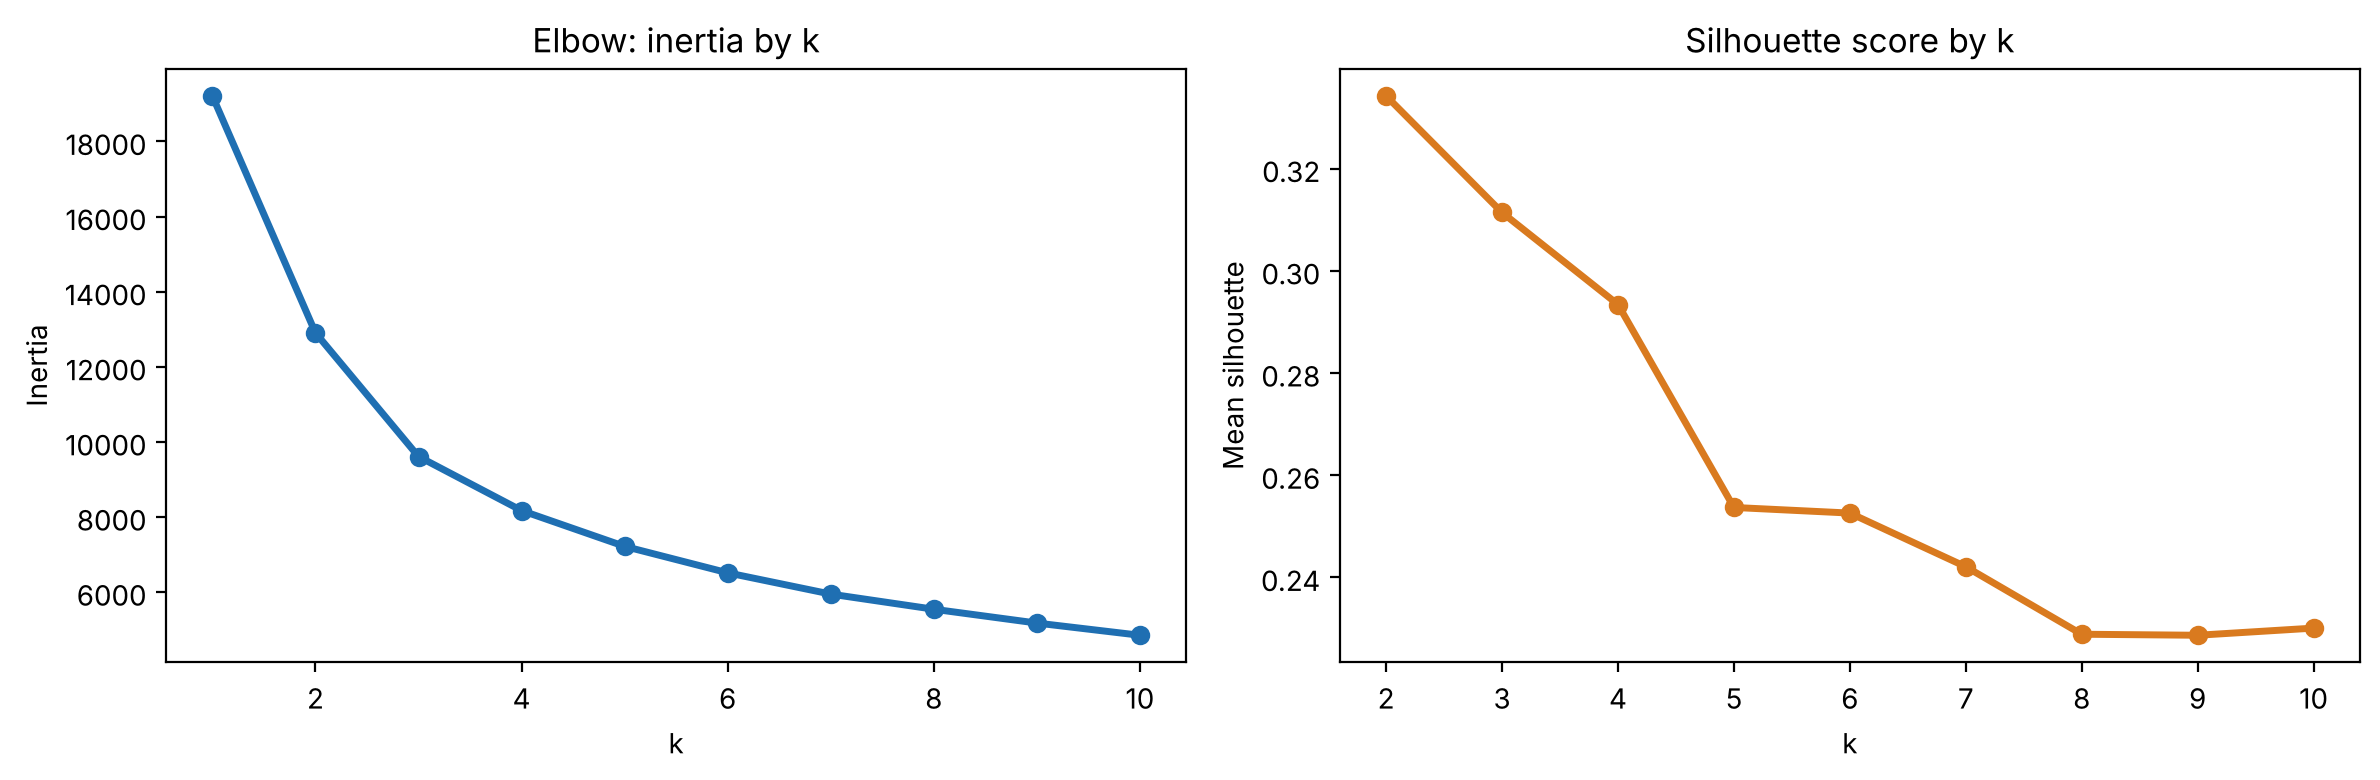

,k,inertia,silhouette
0,1,19212,NaN
1,2,12904,0.3342
2,3,9609,0.3114
3,4,8170,0.2934
4,5,7216,0.2537
5,6,6512,0.2526
6,7,5945,0.2421
7,8,5542,0.2289
8,9,5174,0.2287
9,10,4849,0.2301


In [5]:
rows = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    rows.append({'k': k, 'inertia': round(km.inertia_), 'silhouette': round(silhouette_score(Z, km.labels_), 4) if k > 1 else None})
choose_k = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(choose_k['k'], choose_k['inertia'], color='#1f6fb2', marker='o', linewidth=2.5)
axes[0].set_title('Elbow: inertia by k'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(choose_k['k'][1:], choose_k['silhouette'][1:], color='#d97a1f', marker='o', linewidth=2.5)
axes[1].set_title('Silhouette score by k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Mean silhouette')
plt.tight_layout(); plt.show()
choose_k

The elbow is at k = 2 to 3: inertia drops sharply up to 3 clusters and slowly after that. The silhouette is highest at k = 2 (0.33) and almost as high at k = 3 (0.31), then falls. I use **k = 3** because it scores nearly as well and splits films into groups that are more useful.

## 4. The three market groups

In [6]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Z)
lab = km3.labels_
profile = pd.DataFrame({
    'films': pd.Series(lab).value_counts().sort_index().values,
    'median_gross_$M': (data['$Worldwide'].groupby(lab).median() / 1e6).round(1).values,
    'median_domestic_%': data['Domestic %'].groupby(lab).median().round(1).values,
    'median_votes': data['Vote_Count'].groupby(lab).median().round(0).values,
    'median_rating': data['Rating_num'].groupby(lab).median().round(2).values,
    '%_in_English': (data['Original_Language'].eq('en').groupby(lab).mean() * 100).round(0).values,
    'biggest film': [data.loc[lab == c].sort_values('$Worldwide', ascending=False)['Release Group'].iloc[0] for c in range(3)]})
profile

,films,median_gross_$M,median_domestic_%,median_votes,median_rating,%_in_English,biggest film
0,1639,26.5,0.0,129.0,6.64,15.0,Detective Chinatown 3
1,1499,38.7,67.6,907.0,6.20,98.0,Yogi Bear
2,1665,173.8,41.0,4321.0,6.90,93.0,Avengers: Endgame


The three groups are easy to name:
- **Global blockbusters:** high gross, high votes, about 40% of gross from the U.S., almost all in English.
- **U.S. focused films:** mostly English films that earn about two thirds of their gross in the U.S., with mid level revenue.
- **International market films:** no U.S. release at all (domestic share 0), mostly not in English, few votes on the platform, and the lowest median gross.

This matches the two film populations I found in my Module B EDA (24% of films have no U.S. gross).

# Part 2: Content Groups (MovieLens Tag Genome)

Each film has 1,128 tag scores from 0 to 1 (for example "animation", "big budget", "romantic comedy"). With so many features, distances between films become noisy, so I first standardize the tags and use PCA to keep the 20 strongest directions (about half of the variation), then run k means on those.

In [7]:
combo = pd.read_csv('combined_films.csv')           # built by OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb
genome = pd.read_csv('genome_features.csv', index_col=0)
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0) & sub['ml_movieId'].isin(genome.index)]
G = genome.loc[sub['ml_movieId'].astype(int)].set_index(sub.index)

pca = PCA(n_components=20, random_state=42)
Gp = pca.fit_transform(StandardScaler().fit_transform(G))
print('Films:', len(G), '| variance kept by 20 components:', round(pca.explained_variance_ratio_.sum(), 3))

rows = []
for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Gp)
    rows.append({'k': k, 'inertia': round(km.inertia_), 'silhouette': round(silhouette_score(Gp, km.labels_), 4)})
pd.DataFrame(rows)

Films: 2179 | variance kept by 20 components: 0.516


,k,inertia,silhouette
0,2,1012354,0.2703
1,3,930635,0.1899
2,4,880508,0.1447
3,5,836374,0.1266
4,6,796538,0.1364
5,7,763792,0.1323
6,8,733557,0.1455
7,9,697988,0.1393
8,10,670892,0.1446
9,11,644565,0.1433


The silhouette scores are much lower than in Part 1 (about 0.13 to 0.27). Film content is more of a continuum than a set of separate boxes: a film can be part comedy, part action, part family film. The silhouette is highest at k = 2, but two groups is too coarse to be useful, so I look at **k = 6**.

In [8]:
km6 = KMeans(n_clusters=6, n_init=10, random_state=42).fit(Gp)
lab6 = km6.labels_
hit = (sub['$Worldwide'] > df['$Worldwide'].median())
rows = []
for c in range(6):
    m = lab6 == c
    top_tags = (G[m].mean() - G.mean()).sort_values(ascending=False).index[:4].str.replace('tag_', '')
    rows.append({'films': int(m.sum()),
                 'top tags (above average)': ', '.join(top_tags),
                 'median_gross_$M': round(sub.loc[m, '$Worldwide'].median() / 1e6, 1),
                 '%_hits': round(hit[m].mean() * 100),
                 'biggest film': sub.loc[m].sort_values('$Worldwide', ascending=False)['Release Group'].iloc[0]})
content = pd.DataFrame(rows).sort_values('median_gross_$M', ascending=False)
pd.set_option('display.max_colwidth', None)
content

,films,top tags (above average),median_gross_$M,%_hits,biggest film
0,165,"animation, animated, computer animation, talking animals",245.7,94,Frozen
3,246,"special effects, big budget, action, sci-fi",215.5,87,Avatar
2,334,"suspense, thriller, suspenseful, twists & turns",67.8,65,Skyfall
1,785,"comedy, teen movie, funny, romantic comedy",60.2,58,The Twilight Saga: Breaking Dawn - Part 2
5,307,"great acting, complex, social commentary, imdb top 250",56.1,54,The Lord of the Rings: The Return of the King
4,342,"drama, dramatic, touching, emotional",43.2,46,The Passion of the Christ


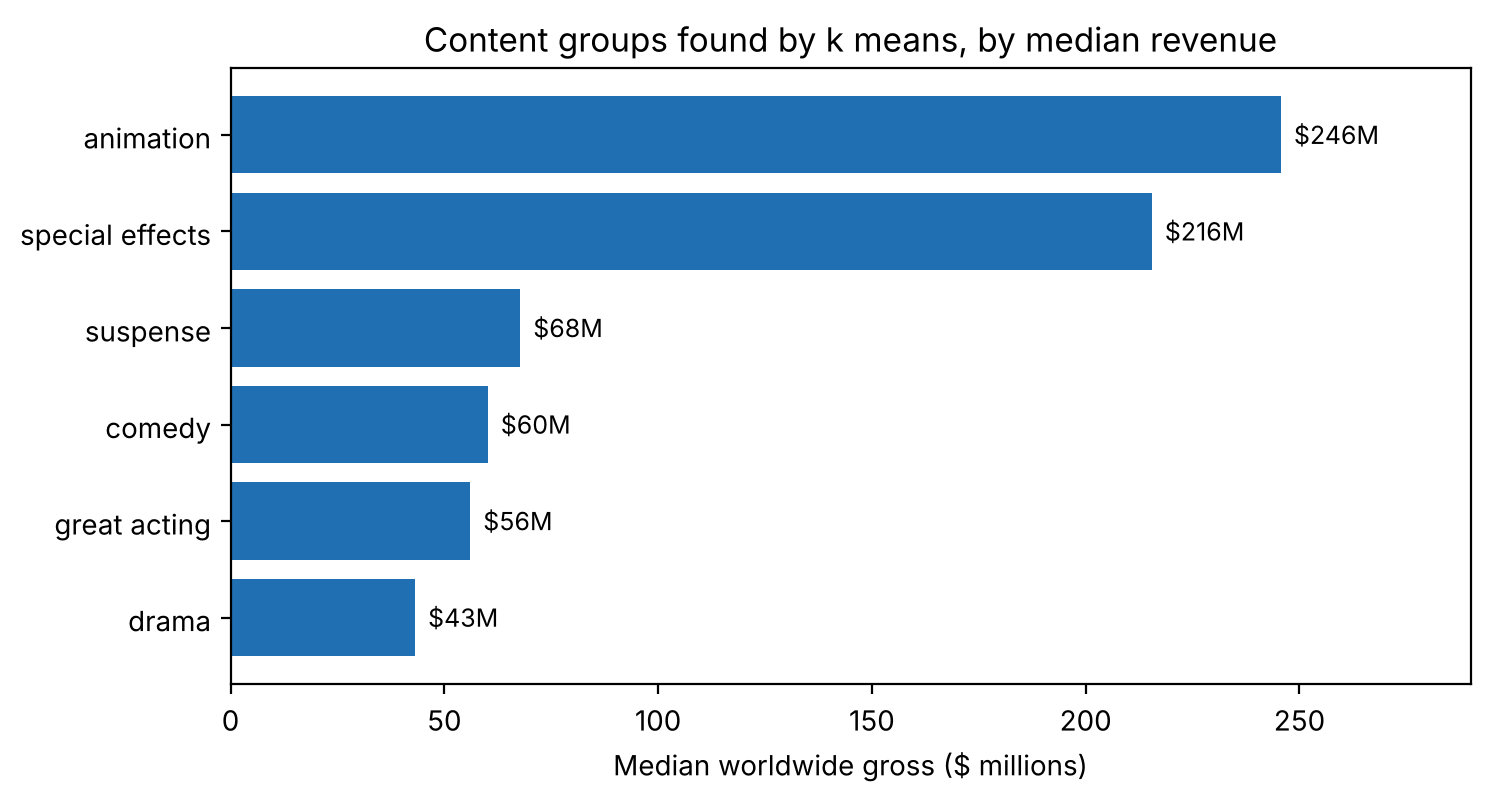

In [9]:
plt.figure(figsize=(8, 4))
names = content['top tags (above average)'].str.split(', ').str[0]
plt.barh(names[::-1], content['median_gross_$M'][::-1], color='#1f6fb2')
for i, v in enumerate(content['median_gross_$M'][::-1]):
    plt.text(v + 3, i, f'${v:.0f}M', va='center', fontsize=9)
plt.xlim(0, 290)
plt.xlabel('Median worldwide gross ($ millions)')
plt.title('Content groups found by k means, by median revenue')
plt.show()

# Conclusions

**The box office data has three clear market groups** (silhouette 0.31 at k = 3):

| Group | Films | Median gross | U.S. share | In English |
|---|---|---|---|---|
| Global blockbusters | 1,665 | $174M | 41% | 93% |
| U.S. focused films | 1,499 | $39M | 68% | 98% |
| International market films | 1,639 | $27M | 0% | 15% |

The international group is the "no U.S. release" population from my EDA, and it explains why language mattered so much in every supervised model: these films earn real money abroad but have few votes on a platform used mostly by Western audiences.

**Scaling changed the answer.** Without standardizing, k means split films almost only by domestic share, because that feature runs from 0 to 100 while the others vary by a few units.

**Content groups are weaker but still useful.** On the tag genome, silhouette scores were low (0.13 to 0.27), so film content is more of a blend than separate boxes. Even so, the six content groups differ in revenue by more than 5 times: **animation** films have a median gross of $246M and 94% are hits, **big budget sci fi and action** $215M and 87%, while **emotional dramas** have $43M and 46%. The "great acting, IMDb top 250" group earns less than the comedy group, another sign that quality does not drive revenue. Because a studio knows what kind of film it is making before release, these content groups could help predict revenue early, which is my main open question from Milestone One.

**Avoiding overfitting in clustering.** There is no target to check against, so the risk is choosing so many clusters that they describe noise. I chose k with both the elbow and the silhouette score instead of picking the k with the lowest inertia (which would always be the largest k), and ran k means 10 times from different starting centroids (`n_init=10`) to avoid a bad local solution.

### Think About It

- **When would we use k means?** When we want a chosen number of compact groups of similar items described by numeric features that can be scaled, such as customer or market segments. It is a poor fit for oddly shaped groups or data with many outliers, since every point must join a cluster.
- **When would we use the silhouette score instead of the elbow method?** When the elbow is unclear. In Part 2 the inertia curve falls smoothly with no sharp bend, so the elbow gives no answer, while the silhouette gives one number to maximize. The cost is speed: the silhouette compares distances between all pairs of points, while the elbow only needs the inertia that k means already computes.
- **Why do we use k means only with the Euclidean metric?** Each k means step moves a centroid to the mean of its cluster, and the mean is the point that minimizes the sum of *squared Euclidean* distances. With Manhattan distance the best center is the median, not the mean, so moving to the mean would no longer reduce the error the algorithm is trying to minimize.